# 02: Cleaning walkthrough

The pipeline itself is `src/ingest.py` and `src/clean.py`. This notebook audits its output using the quarantine ledger, where every rejected row and changed value is recorded. The full generated report is `reports/data_quality.md`.

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd

from src.clean import load_dataset
from src.utils import load_config, project_path

cfg = load_config()
df = load_dataset(cfg)
ledger = pd.read_parquet(project_path("interim", cfg) / "quarantine.parquet")
print(f"{len(ledger):,} ledger entries, {len(df):,} rows in the final dataset")

105,191 ledger entries, 181,200 rows in the final dataset


## What each rule did

In [2]:
display(ledger.groupby(["stage", "rule", "column"], sort=False).size().rename("entries").reset_index())

,stage,rule,column,entries
0,ingest,negative_volume,traffic_volume,241
1,ingest,speed_out_of_range,avg_speed,237
2,ingest,occupancy_out_of_range,occupancy,234
3,dedup,duplicate_key,row,1767
4,outliers,volume_from_vehicle_count,traffic_volume,4587
5,outliers,speed_from_travel_time,avg_speed,4579
6,outliers,occupancy_blanked,occupancy,229
7,missing,row_added_to_grid,row,4499
8,missing,interpolated,traffic_volume,4498
9,missing,window_median,traffic_volume,1


## Repairs are exact where a redundant column exists

Volume rebuilt from `vehicle_count` and speed rebuilt from `travel_time` are compared with the values that survive on valid rows.

In [3]:
sensor = df[df.vol_source == "sensor"]
print("Sensor rows where volume != vehicle_count:", int((sensor.traffic_volume != sensor.vehicle_count).sum()))
valid = df[df.speed_source == "sensor"]
implied = valid.seg_length_km * 60 / valid.travel_time
print(f"Speed implied by travel time vs sensor speed on valid rows: max abs error {(implied - valid.avg_speed).abs().max():.2f} km/h, mean {(implied - valid.avg_speed).abs().mean():.3f} km/h")

Sensor rows where volume != vehicle_count: 0
Speed implied by travel time vs sensor speed on valid rows: max abs error 0.36 km/h, mean 0.043 km/h


## One repaired stretch

A day containing an absent window: the markers show rows the pipeline estimated.

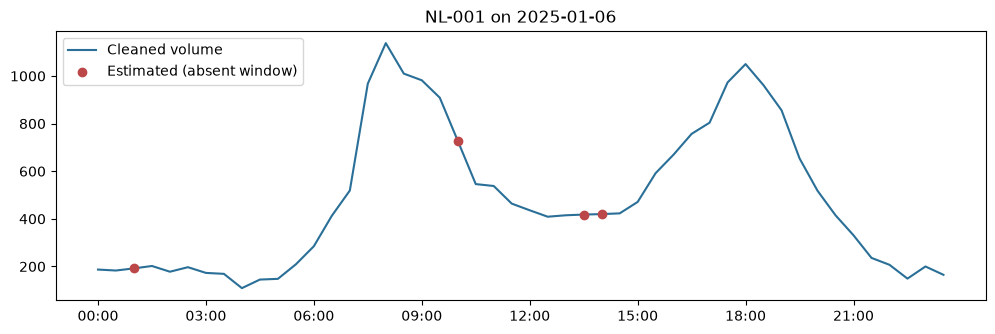

In [4]:
row = df[df.row_imputed & (df.date > "2025-01-05")].iloc[0]
day = df[(df.road_id == row.road_id) & (df.date == row.date)]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(day.time, day.traffic_volume, color="#2a6f97", label="Cleaned volume")
gaps = day[day.row_imputed]
ax.scatter(gaps.time, gaps.traffic_volume, color="#bc4749", zorder=3, label="Estimated (absent window)")
ax.set_xticks(ax.get_xticks()[::6]); ax.set_title(f"{row.road_id} on {row.date}"); ax.legend()
plt.show()

## Final checks

The pipeline fails rather than continue if any of these break. They're re-run here against the saved dataset.

In [5]:
from src.clean import final_checks
final_checks(df, 181_200, cfg)
print("Passed: no nulls in modelling columns, 181,200 rows, unique keys, ranges and vocabulary valid")
display(df.congestion_level.value_counts().to_frame("windows"))

Passed: no nulls in modelling columns, 181,200 rows, unique keys, ranges and vocabulary valid


,windows
congestion_level,
Free-flow,111276
Moderate,43208
Heavy,16787
Severe,9929
